Loading weights:   0%|          | 0/323 [00:00<?, ?it/s]

CLS token shape: torch.Size([1, 1, 768])
Patch tokens shape: torch.Size([1, 1024, 768])


/tmp/ipykernel_546/3854772049.py:86: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap("tab10", len(classes))


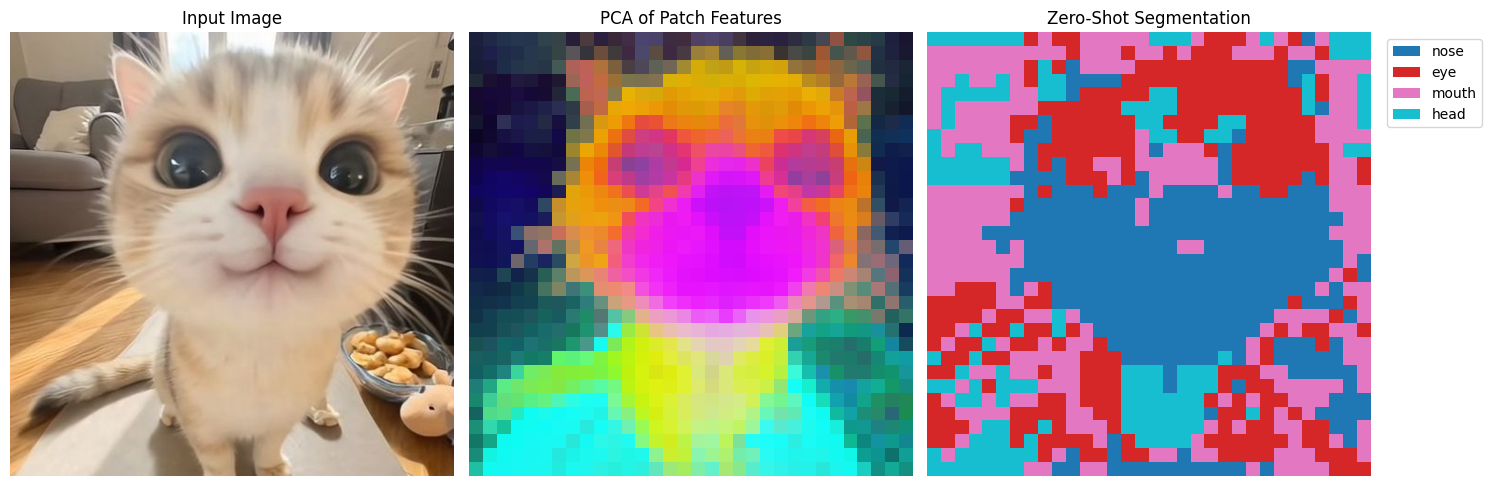

Predicted class: eye


In [3]:
# Required packages
# pip install transformers torch torchvision sentencepiece scikit-learn matplotlib

import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from PIL import Image
import requests
from torchvision import transforms
from transformers import AutoModel

# -------------------------------------------------------------------------
# 1. Load model (matches your "Loading weights: 100%" step)
# -------------------------------------------------------------------------
model = AutoModel.from_pretrained(
    "google/tipsv2-b14",
    trust_remote_code=True
)
model.eval().cuda()  # or .eval() for CPU

# -------------------------------------------------------------------------
# 2. Load and preprocess image
# -------------------------------------------------------------------------
image_path = "/content/5da360c98b9af0ad709fe18606992229.jpg"
image = Image.open(image_path).convert("RGB")

# TIPSv2 expects [0, 1] range — just ToTensor(), NO ImageNet normalization
transform = transforms.Compose([
    transforms.Resize((448, 448)),
    transforms.ToTensor(),
])
pixel_values = transform(image).unsqueeze(0).cuda()

# -------------------------------------------------------------------------
# 3. Encode image and extract features
# -------------------------------------------------------------------------
with torch.no_grad():
    out = model.encode_image(pixel_values)

# out.cls_token:     (1, 1, 768)   — global image embedding
# out.patch_tokens:  (1, 1024, 768) — spatial patch features (32×32 grid for 448px)
print(f"CLS token shape: {out.cls_token.shape}")
print(f"Patch tokens shape: {out.patch_tokens.shape}")

# -------------------------------------------------------------------------
# 4. Prepare 3-panel visualization (matches your Figure size 1500×500)
# -------------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# --- Panel 1: Original Image ---
axes[0].imshow(image.resize((448, 448)))
axes[0].set_title("Input Image")
axes[0].axis("off")

# --- Panel 2: PCA of Patch Embeddings ---
# Reshape patches to spatial grid: (1, 32, 32, 768)
spatial = out.patch_tokens.reshape(1, 32, 32, 768)
feat = spatial[0].detach().cpu().numpy().reshape(-1, 768)

# PCA to 3 components, sigmoid for contrast
pca = PCA(n_components=3, whiten=True).fit_transform(feat)
pca = pca.reshape(32, 32, 3)
pca_rgb = 1 / (1 + np.exp(-2.0 * pca))  # sigmoid for [0,1] display

axes[1].imshow(pca_rgb)
axes[1].set_title("PCA of Patch Features")
axes[1].axis("off")

# --- Panel 3: Zero-Shot Segmentation ---
# Example: classify each patch against text labels
classes = ["nose", "eye", "mouth", "head"]
text_emb = model.encode_text(classes)  # (5, 768)
text_emb = F.normalize(text_emb, dim=-1)

# Normalize patch tokens and compute cosine similarity
patches = out.patch_tokens[0]  # (1024, 768)
patches = F.normalize(patches, dim=-1)
similarity = patches @ text_emb.T  # (1024, 5)

# Get best class per patch and reshape to 32×32
seg_map = similarity.argmax(dim=1).cpu().numpy().reshape(32, 32)

# Colorize segmentation
cmap = plt.cm.get_cmap("tab10", len(classes))
axes[2].imshow(seg_map, cmap=cmap, vmin=-0.5, vmax=len(classes)-0.5)
axes[2].set_title("Zero-Shot Segmentation")
axes[2].axis("off")

# Add class legend
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=cmap(i), label=classes[i]) for i in range(len(classes))]
axes[2].legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(1.02, 1))

plt.tight_layout()
plt.show()

# -------------------------------------------------------------------------
# 5. Zero-shot classification (optional)
# -------------------------------------------------------------------------
cls_token = F.normalize(out.cls_token[:, 0, :], dim=-1)
text_emb_cls = F.normalize(model.encode_text(classes), dim=-1)
similarity_cls = cls_token @ text_emb_cls.T
predicted_class = classes[similarity_cls.argmax()]
print(f"Predicted class: {predicted_class}")